# 11 - Robustness checks

**Goal:** stress-test the main findings with three extra analyses.

1. **Product mix and churn.** Does *what* a customer buys (Christmas items, number of products, price level, basket size) add anything to the churn model beyond recency, frequency and value?
2. **Stability across cutoff dates.** The churn back-test in notebook 05 uses one cutoff (30 Jun 2011). Does the "silent > 90 days" rule hold up when the same test is repeated at four other cutoffs?
3. **Uncertainty.** Bootstrap and exact intervals around the headline numbers (repeat rate, sales growth, concentration, rule precision and recall, new-customer drop, 90-day repeat rates).

**Input:** `data/processed/transactions_clean.csv`
**Outputs:** `data/processed/robustness_*.csv`, `reports/figures/11_*.png`

**Design notes**
- The churn label is the same as in notebook 05: no purchase in the 161 days after the cutoff. The base is customers with a purchase in the 12 months before the cutoff. Features use history only.
- For the 30 Jun 2011 cutoff the holdout runs to the end of the data, so this notebook must reproduce notebook 05's base (4,326 customers) and churn rate (43.9%). A check below asserts it.
- "Product category" does not exist in the data. Product features are derived from descriptions and stock codes, and the Christmas keyword list is a documented heuristic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from pathlib import Path
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

ROOT = Path.cwd().parent  # notebook runs from notebooks/
PROC = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 200)

RNG = np.random.default_rng(20261102)
N_BOOT = 2000
HOLDOUT_DAYS = 161
XMAS = r"CHRISTMAS|XMAS|SANTA|REINDEER|ADVENT|SNOWMAN|SNOWFLAKE|TINSEL|STOCKING|NOEL"

## 1. Load and keep only what is needed

The full table is large, so the pieces the analysis needs are extracted first and the rest is released.

In [2]:
usecols = ["invoice", "stock_code", "description", "quantity", "invoice_date", "customer_id", "country",
           "is_cancellation", "is_product", "has_customer", "line_total", "first_purchase_month"]
df = pd.read_csv(
    PROC / "transactions_clean.csv", usecols=usecols,
    parse_dates=["invoice_date", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": "category", "country": "category", "customer_id": "Int64"},
)
DATA_END = df.invoice_date.max()

# cluster-level sales for the sales-growth interval: a cluster is a tracked customer, or one guest invoice
sales_all = df[~df.is_cancellation].copy()
sales_all["cluster"] = np.where(sales_all.has_customer, "c" + sales_all.customer_id.astype(str), "g" + sales_all.invoice)
sales_all["year"] = sales_all.invoice_date.dt.year
in_window = sales_all[(sales_all.invoice_date.dt.month <= 11) & sales_all.year.isin([2010, 2011])]
cluster_sales = in_window.pivot_table(index="cluster", columns="year", values="line_total", aggfunc="sum", fill_value=0.0)

cancels = df[df.is_cancellation & df.has_customer][["customer_id", "invoice_date", "line_total"]].copy()
tracked = df[(~df.is_cancellation) & df.has_customer].drop(columns=["is_cancellation", "has_customer"]).copy()
tracked["is_xmas"] = tracked.description.fillna("").str.upper().str.contains(XMAS)
tracked = tracked.drop(columns="description")
tracked["customer_id"] = tracked.customer_id.astype("int64")
cancels["customer_id"] = cancels.customer_id.astype("int64")
del df, sales_all, in_window
print(f"{len(tracked):,} tracked sale lines | {tracked.customer_id.nunique():,} customers | data ends {DATA_END}")
print(f"Christmas-keyword lines: {tracked.is_xmas.mean():.1%} of tracked lines")

779,425 tracked sale lines | 5,878 customers | data ends 2011-12-09 12:50:00
Christmas-keyword lines: 4.7% of tracked lines


## 2. Features and churn label at any cutoff

`build_features(cutoff)` is the same logic as notebook 05 (recency, order days, average gap, trailing net sales, cancellation rate, UK flag) plus five product features: Christmas share of spend, number of distinct products, average unit price, units per invoice, and the share of spend on the single biggest product.

In [3]:
def build_features(cutoff, holdout_end=None):
    cutoff = pd.Timestamp(cutoff) + pd.Timedelta(hours=23, minutes=59, seconds=59)
    holdout_end = holdout_end or cutoff + pd.Timedelta(days=HOLDOUT_DAYS)
    window_start = cutoff - pd.Timedelta(days=365)
    hist = tracked[tracked.invoice_date <= cutoff]
    base_ids = hist.loc[hist.invoice_date > window_start, "customer_id"].unique()

    day = hist.invoice_date.dt.normalize()
    days = pd.DataFrame({"customer_id": hist.customer_id, "day": day}).drop_duplicates().sort_values(["customer_id", "day"])
    days["gap"] = days.groupby("customer_id").day.diff().dt.days
    gd = days.groupby("customer_id")
    feat = pd.DataFrame({
        "recency": (cutoff.normalize() - gd.day.max()).dt.days,
        "order_days": gd.size(),
        "avg_gap": gd.gap.mean(),
        "invoices": hist.groupby("customer_id").invoice.nunique(),
        "uk": (hist.groupby("customer_id").country.first() == "United Kingdom").astype(int),
    })
    feat["overdue_ratio"] = feat.recency / feat.avg_gap.where(feat.avg_gap > 0)

    win = hist[hist.invoice_date > window_start]
    c_hist = cancels[cancels.invoice_date <= cutoff]
    c_win = c_hist[c_hist.invoice_date > window_start]
    feat["trailing_rev"] = (win.groupby("customer_id").line_total.sum().add(c_win.groupby("customer_id").line_total.sum(), fill_value=0)).reindex(feat.index).fillna(0).round(2)
    sales_total = hist.groupby("customer_id").line_total.sum()
    feat["cancel_rate"] = ((-c_hist.groupby("customer_id").line_total.sum()) / sales_total).reindex(feat.index).fillna(0).clip(0, 1)

    ph = hist[hist.is_product]
    pg = ph.groupby("customer_id")
    spend, units = pg.line_total.sum(), pg.quantity.sum()
    by_code = ph.groupby(["customer_id", "stock_code"], observed=True).line_total.sum()
    feat["xmas_share"] = (ph[ph.is_xmas].groupby("customer_id").line_total.sum() / spend).reindex(feat.index).fillna(0).clip(0, 1)
    feat["n_products"] = pg.stock_code.nunique()
    feat["avg_unit_price"] = spend / units
    feat["units_per_invoice"] = units / pg.invoice.nunique()
    feat["top_product_share"] = by_code.groupby(level=0).max() / spend

    feat = feat.loc[feat.index.isin(base_ids)]
    future = tracked.loc[(tracked.invoice_date > cutoff) & (tracked.invoice_date <= holdout_end), "customer_id"].unique()
    feat["churned"] = (~feat.index.isin(future)).astype(int)
    feat = feat.replace([np.inf, -np.inf], np.nan)
    feat.attrs["missing_product_features"] = int(feat[["n_products", "avg_unit_price", "units_per_invoice", "top_product_share"]].isna().any(axis=1).sum())
    return feat

FINAL = "2011-06-30"
final = build_features(FINAL, holdout_end=DATA_END)
print(f"cutoff {FINAL}: base {len(final):,} customers, churn rate {final.churned.mean():.1%}, {final.attrs['missing_product_features']} without product lines (kept in the base; excluded only from the product-feature models)")
assert 4320 <= len(final) <= 4330, "base should match notebook 05 (4,326 customers)"
assert abs(final.churned.mean() - 0.439) < 0.004, "churn rate should match notebook 05 (43.9%)"
final[["recency", "invoices", "trailing_rev", "xmas_share", "n_products", "avg_unit_price", "units_per_invoice", "top_product_share"]].describe().T

cutoff 2011-06-30: base 4,326 customers, churn rate 43.9%, 8 without product lines (kept in the base; excluded only from the product-feature models)


,count,mean,std,min,25%,50%,75%,max
recency,"4,326.000",132.092,104.969,0.000,35.000,104.000,228.000,364.000
invoices,"4,326.000",6.041,11.252,1.000,2.000,3.000,7.000,275.000
trailing_rev,"4,326.000","1,792.121","7,393.458","-13,238.700",293.985,629.895,"1,521.342","252,294.590"
xmas_share,"4,326.000",0.041,0.090,0.000,0.000,0.002,0.045,1.000
n_products,"4,318.000",79.285,105.270,1.000,20.000,47.000,99.000,"2,052.000"
avg_unit_price,"4,318.000",2.293,6.219,0.134,1.446,1.839,2.345,329.888
units_per_invoice,"4,318.000",248.194,"1,423.860",1.000,93.000,153.243,258.000,"87,167.000"
top_product_share,"4,318.000",0.155,0.179,0.010,0.058,0.094,0.169,1.000


## 3. Product mix and churn

First univariate: does each product feature differ between churned and retained customers? Then multivariate: does a model with the product features fit better than the baseline (recency, frequency, value, cancellations, UK)?

In [4]:
PRODUCT = ["xmas_share", "n_products", "avg_unit_price", "units_per_invoice", "top_product_share"]

def compare(frame, col):
    a, b = frame.loc[frame.churned == 1, col], frame.loc[frame.churned == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"feature": col, "median_churned": a.median(), "median_retained": b.median(),
            "P(churned > retained)": u / (len(a) * len(b)), "p_value": p}

model_frame = final.dropna(subset=PRODUCT)  # same rows for every model, so they are comparable
print(f"{len(model_frame):,} customers in the product-feature models ({len(final) - len(model_frame)} excluded: no product lines)")
uni = pd.DataFrame([compare(model_frame, c) for c in PRODUCT])
uni

4,318 customers in the product-feature models (8 excluded: no product lines)


,feature,median_churned,median_retained,P(churned > retained),p_value
0,xmas_share,0.000,0.009,0.450,0.000
1,n_products,29.000,69.000,0.294,0.000
2,avg_unit_price,1.897,1.807,0.536,0.000
3,units_per_invoice,131.167,175.633,0.396,0.000
4,top_product_share,0.113,0.081,0.630,0.000


In [5]:
def design(frame, with_product):
    X = pd.DataFrame({
        "days silent (x2)": np.log2(1 + frame.recency),
        "invoices (x2)": np.log2(1 + frame.invoices),
        "trailing sales (x2)": np.log2(1 + frame.trailing_rev.clip(lower=0)),
        "cancel rate": frame.cancel_rate,
        "UK customer": frame.uk,
    })
    if with_product:
        X["Christmas share of spend"] = frame.xmas_share
        X["products bought (x2)"] = np.log2(1 + frame.n_products)
        X["avg unit price (x2)"] = np.log2(frame.avg_unit_price.clip(lower=0.01))
        X["units per invoice (x2)"] = np.log2(frame.units_per_invoice.clip(lower=0.01))
        X["top product share"] = frame.top_product_share
    return sm.add_constant(X)

def auc(y, p):
    u, _ = stats.mannwhitneyu(p[y == 1], p[y == 0])
    return u / ((y == 1).sum() * (y == 0).sum())

base_fit = sm.Logit(model_frame.churned, design(model_frame, False)).fit(disp=0)
full_fit = sm.Logit(model_frame.churned, design(model_frame, True)).fit(disp=0)
lr = 2 * (full_fit.llf - base_fit.llf)
df_extra = len(PRODUCT)
lr_p = stats.chi2.sf(lr, df_extra)

comparison = pd.DataFrame({
    "baseline": {"log-likelihood": base_fit.llf, "AIC": base_fit.aic, "pseudo R2": base_fit.prsquared, "in-sample AUC": auc(model_frame.churned.to_numpy(), np.asarray(base_fit.predict()))},
    "with product features": {"log-likelihood": full_fit.llf, "AIC": full_fit.aic, "pseudo R2": full_fit.prsquared, "in-sample AUC": auc(model_frame.churned.to_numpy(), np.asarray(full_fit.predict()))},
})
print(f"likelihood-ratio test for the {df_extra} product features: chi2 = {lr:.1f}, p = {lr_p:.3g}")
comparison

likelihood-ratio test for the 5 product features: chi2 = 19.7, p = 0.00141


,baseline,with product features
log-likelihood,"-2,369.986","-2,360.122"
AIC,"4,751.971","4,742.244"
pseudo R2,0.199,0.203
in-sample AUC,0.786,0.788


In [6]:
odds = pd.DataFrame({
    "odds_ratio": np.exp(full_fit.params), "ci_low": np.exp(full_fit.conf_int()[0]), "ci_high": np.exp(full_fit.conf_int()[1]), "p_value": full_fit.pvalues,
}).drop(index="const")
odds

,odds_ratio,ci_low,ci_high,p_value
days silent (x2),1.321,1.258,1.388,0.000
invoices (x2),0.700,0.598,0.818,0.000
trailing sales (x2),0.700,0.626,0.783,0.000
cancel rate,0.778,0.293,2.065,0.614
UK customer,0.958,0.742,1.237,0.741
Christmas share of spend,1.811,0.790,4.152,0.161
products bought (x2),0.937,0.856,1.027,0.163
avg unit price (x2),1.314,1.112,1.552,0.001
units per invoice (x2),1.156,1.011,1.322,0.034
top product share,1.213,0.647,2.273,0.547


### Out-of-time check

Train on two *earlier* cutoffs whose 161-day holdouts end before 30 Jun 2011 (so no label leaks from the future), then score the 30 Jun 2011 base.

In [7]:
train = pd.concat([build_features(c) for c in ("2010-11-30", "2010-12-31")]).dropna(subset=PRODUCT)
y_test = model_frame.churned.to_numpy()
oot = {}
for label, with_product in (("baseline", False), ("with product features", True)):
    fit = sm.Logit(train.churned, design(train, with_product)).fit(disp=0)
    pred = np.asarray(fit.predict(design(model_frame, with_product)))
    oot[label] = auc(y_test, pred)
oot_table = pd.Series(oot, name="out-of-time AUC (trained on Nov-Dec 2010 cutoffs, tested at 30 Jun 2011)").to_frame()
print(f"training rows: {len(train):,} (two cutoffs pooled); test rows: {len(model_frame):,}")
oot_table

training rows: 8,445 (two cutoffs pooled); test rows: 4,318


,"out-of-time AUC (trained on Nov-Dec 2010 cutoffs, tested at 30 Jun 2011)"
baseline,0.778
with product features,0.778


## 4. Does the early-warning rule hold up across cutoff dates?

The same base, label and rules as notebook 05, repeated at five cutoffs. Each holdout is 161 days and ends before the data does (the last one runs to the end of the data).

In [8]:
CUTOFFS = ["2010-11-30", "2010-12-31", "2011-02-28", "2011-04-30", "2011-06-30"]
features = {c: (final if c == FINAL else build_features(c)) for c in CUTOFFS}

def rule_metrics(frame, flag):
    flagged = frame[flag]
    churners = frame[frame.churned == 1]
    precision = flagged.churned.mean() if len(flagged) else np.nan
    return precision, flagged.churned.sum() / frame.churned.sum(), flagged.loc[flagged.churned == 1, "trailing_rev"].clip(lower=0).sum() / churners.trailing_rev.clip(lower=0).sum()

rows = []
for c, f in features.items():
    row = {"cutoff": c, "base": len(f), "churn_rate": f.churned.mean()}
    for days in (60, 90, 120):
        p, r, rev = rule_metrics(f, f.recency > days)
        row.update({f"p{days}": p, f"r{days}": r, f"rev{days}": rev})
    elig = f[f.order_days >= 3]
    p, r, _ = rule_metrics(elig, elig.overdue_ratio > 1.5)
    row.update({"gap_rule_precision": p, "gap_rule_base_rate": elig.churned.mean(), "gap_rule_flagged": int((elig.overdue_ratio > 1.5).sum())})
    rows.append(row)
cutoff_table = pd.DataFrame(rows).set_index("cutoff")
cutoff_table[["base", "churn_rate", "p60", "r60", "p90", "r90", "rev90", "p120", "r120"]]

,base,churn_rate,p60,r60,p90,r90,rev90,p120,r120
cutoff,,,,,,,,,
2010-11-30,4266,0.546,0.709,0.554,0.755,0.447,0.349,0.774,0.381
2010-12-31,4231,0.548,0.674,0.657,0.720,0.491,0.392,0.763,0.389
2011-02-28,4276,0.530,0.639,0.856,0.673,0.760,0.628,0.715,0.554
2011-04-30,4332,0.506,0.639,0.817,0.673,0.746,0.653,0.697,0.697
2011-06-30,4326,0.439,0.577,0.818,0.606,0.746,0.657,0.629,0.661


In [9]:
cutoff_table[["gap_rule_flagged", "gap_rule_precision", "gap_rule_base_rate"]].assign(lift=lambda d: d.gap_rule_precision / d.gap_rule_base_rate)

,gap_rule_flagged,gap_rule_precision,gap_rule_base_rate,lift
cutoff,,,,
2010-11-30,330,0.485,0.310,1.562
2010-12-31,482,0.444,0.334,1.330
2011-02-28,779,0.427,0.331,1.293
2011-04-30,873,0.466,0.319,1.461
2011-06-30,845,0.433,0.279,1.554


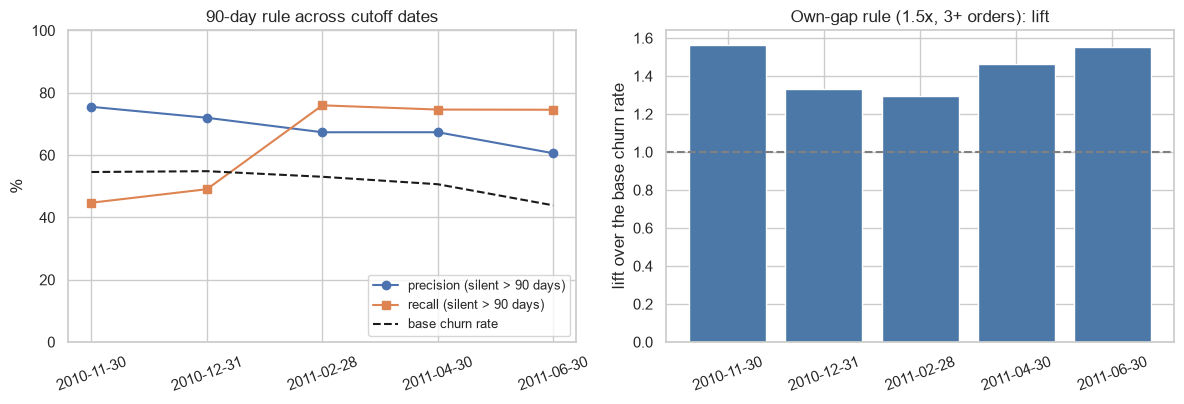

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(CUTOFFS))
for col, label, style in (("p90", "precision (silent > 90 days)", "o-"), ("r90", "recall (silent > 90 days)", "s-"), ("churn_rate", "base churn rate", "k--")):
    axes[0].plot(x, cutoff_table[col] * 100, style, label=label)
axes[0].set_xticks(x, CUTOFFS, rotation=20)
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 100)
axes[0].set_title("90-day rule across cutoff dates")
axes[0].legend(loc="lower right", fontsize=9)
lift = cutoff_table.gap_rule_precision / cutoff_table.gap_rule_base_rate
axes[1].bar(x, lift, color="#4C78A8")
axes[1].axhline(1, color="grey", ls="--")
axes[1].set_xticks(x, CUTOFFS, rotation=20)
axes[1].set_ylabel("lift over the base churn rate")
axes[1].set_title("Own-gap rule (1.5x, 3+ orders): lift")
fig.tight_layout()
fig.savefig(FIGURES / "11_cutoff_stability.png", dpi=150)
plt.show()

## 5. Uncertainty around the headline numbers

Customers are resampled with replacement (a cluster bootstrap), because one customer's orders are not independent of each other. Sales growth also resamples guest orders, one invoice at a time. New-customer counts use an exact binomial interval and a sign test across months, because counts of arrivals are not a sample of customers.

In [11]:
def boot_stat(n, stat_fn, n_boot=N_BOOT, chunk=250):
    """Bootstrap a statistic of index arrays: stat_fn(idx) -> one value per resample (idx has shape chunk x n)."""
    out = []
    for _ in range(0, n_boot, chunk):
        idx = RNG.integers(0, n, size=(chunk, n))
        out.append(np.asarray(stat_fn(idx)))
    return np.concatenate(out)[:n_boot]

def interval(values):
    return np.percentile(values, [2.5, 97.5])

results = []
def add(metric, estimate, lo, hi, method, unit="%"):
    results.append({"metric": metric, "estimate": estimate, "ci_low": lo, "ci_high": hi, "method": method, "unit": unit})

# repeat purchase rate (customers with 2+ invoices)
inv = tracked.groupby("customer_id").invoice.nunique().to_numpy()
rep = (inv >= 2).astype(float)
lo, hi = interval(boot_stat(len(rep), lambda idx: rep[idx].mean(axis=1)))
add("Repeat purchase rate (2+ orders)", rep.mean() * 100, lo * 100, hi * 100, "cluster bootstrap over customers")

# Jan-Nov sales growth, 2011 against 2010
s10, s11 = cluster_sales[2010].to_numpy(), cluster_sales[2011].to_numpy()
growth = boot_stat(len(s10), lambda idx: s11[idx].sum(axis=1) / s10[idx].sum(axis=1) - 1, chunk=100)
lo, hi = interval(growth)
add("Sales growth, Jan-Nov 2011 vs 2010", (s11.sum() / s10.sum() - 1) * 100, lo * 100, hi * 100, "cluster bootstrap (customers and guest invoices)")

# top 10% share of tracked sales
cust_sales = tracked.groupby("customer_id").line_total.sum().to_numpy()
k = int(len(cust_sales) * 0.10)
def top_share(idx):
    s = np.sort(cust_sales[idx], axis=1)[:, ::-1]
    return s[:, :k].sum(axis=1) / s.sum(axis=1)
lo, hi = interval(boot_stat(len(cust_sales), top_share, n_boot=1000, chunk=100))
srt = np.sort(cust_sales)[::-1]
add("Top 10% of customers' share of sales", srt[:k].sum() / srt.sum() * 100, lo * 100, hi * 100, "cluster bootstrap over customers")

# churn back-test at the final cutoff
churned = final.churned.to_numpy().astype(float)
flag = (final.recency > 90).to_numpy().astype(float)
lo, hi = interval(boot_stat(len(final), lambda idx: churned[idx].mean(axis=1)))
add("Base churn rate (161-day holdout)", churned.mean() * 100, lo * 100, hi * 100, "cluster bootstrap over customers")
prec = lambda idx: (flag[idx] * churned[idx]).sum(axis=1) / flag[idx].sum(axis=1)
rec = lambda idx: (flag[idx] * churned[idx]).sum(axis=1) / churned[idx].sum(axis=1)
lo, hi = interval(boot_stat(len(final), prec))
add("90-day rule: precision", (flag * churned).sum() / flag.sum() * 100, lo * 100, hi * 100, "cluster bootstrap over customers")
lo, hi = interval(boot_stat(len(final), rec))
add("90-day rule: recall", (flag * churned).sum() / churned.sum() * 100, lo * 100, hi * 100, "cluster bootstrap over customers")

pd.DataFrame(results)

,metric,estimate,ci_low,ci_high,method,unit
0,Repeat purchase rate (2+ orders),72.389,71.164,73.512,cluster bootstrap over customers,%
1,"Sales growth, Jan-Nov 2011 vs 2010",1.900,-4.853,9.665,cluster bootstrap (customers and guest invoices),%
2,Top 10% of customers' share of sales,63.895,59.497,67.813,cluster bootstrap over customers,%
3,Base churn rate (161-day holdout),43.874,42.372,45.308,cluster bootstrap over customers,%
4,90-day rule: precision,60.600,58.631,62.560,cluster bootstrap over customers,%
5,90-day rule: recall,74.552,72.678,76.315,cluster bootstrap over customers,%


In [12]:
# new customers, Jun-Nov 2011 against 2010: counts per month, exact interval and a sign test
first = tracked.groupby("customer_id").first_purchase_month.first()
monthly = first[first.dt.month.between(6, 11) & first.dt.year.isin([2010, 2011])]
by_month = monthly.groupby([monthly.dt.year, monthly.dt.month]).size().unstack(0)
by_month.columns = ["2010", "2011"]
n10, n11 = int(by_month["2010"].sum()), int(by_month["2011"].sum())
ci = stats.binomtest(n11, n10 + n11).proportion_ci(method="exact")
ratio = lambda p: p / (1 - p)
add("New customers Jun-Nov, 2011 vs 2010", (n11 / n10 - 1) * 100, (ratio(ci.low) - 1) * 100, (ratio(ci.high) - 1) * 100,
    "exact binomial interval, assuming monthly arrivals behave like Poisson counts")
lower = int((by_month["2011"] < by_month["2010"]).sum())
sign = stats.binomtest(lower, len(by_month), 0.5)
print(f"months where 2011 is below 2010: {lower} of {len(by_month)} (sign test p = {sign.pvalue:.3f})")
by_month.assign(change=lambda d: d["2011"] / d["2010"] - 1)

months where 2011 is below 2010: 6 of 6 (sign test p = 0.031)


,2010,2011,change
first_purchase_month,,,
6,270,108,-0.600
7,186,102,-0.452
8,162,106,-0.346
9,243,189,-0.222
10,377,221,-0.414
11,325,191,-0.412


In [13]:
# 90-day repeat rate by acquisition period (new customers who placed a 2nd order within 90 days)
orders = tracked.groupby(["customer_id", "invoice"]).invoice_date.min().reset_index().sort_values(["customer_id", "invoice_date"])
orders["n"] = orders.groupby("customer_id").cumcount()
first_o = orders[orders.n == 0].set_index("customer_id").invoice_date
second_o = orders[orders.n == 1].set_index("customer_id").invoice_date
per = pd.DataFrame({"first": first_o, "second": second_o.reindex(first_o.index)})
per = per[per["first"] <= DATA_END - pd.Timedelta(days=90)].copy()
per["repeat"] = (per.second - per["first"]).dt.total_seconds() / 86400 <= 90
per["period"] = per["first"].map(lambda d: "Dec 2009 (left-censored)" if (d.year, d.month) == (2009, 12) else f"{d.year} H{1 if d.month <= 6 else 2}")
periods = ["2010 H1", "2010 H2", "2011 H1"]
table = per[per.period.isin(periods)].groupby("period").repeat.agg(["sum", "count"]).reindex(periods)
wil = [proportion_confint(r.loc["sum"], r.loc["count"], method="wilson") for _, r in table.iterrows()]
repeat_table = pd.DataFrame({"customers": table["count"], "repeat_rate_%": table["sum"] / table["count"] * 100,
                             "ci_low_%": [w[0] * 100 for w in wil], "ci_high_%": [w[1] * 100 for w in wil]})
chi2, p_all, _, _ = stats.chi2_contingency(np.array([table["sum"], table["count"] - table["sum"]]))
z, p_h1h2 = sm.stats.proportions_ztest(table["sum"].iloc[[0, 1]].to_numpy(), table["count"].iloc[[0, 1]].to_numpy())
z2, p_h2_11 = sm.stats.proportions_ztest(table["sum"].iloc[[1, 2]].to_numpy(), table["count"].iloc[[1, 2]].to_numpy())
print(f"chi-square across the three periods: p = {p_all:.4f}")
print(f"2010 H1 vs 2010 H2: p = {p_h1h2:.4f} | 2010 H2 vs 2011 H1: p = {p_h2_11:.4f}")
for period, r in repeat_table.iterrows():
    add(f"90-day repeat rate, acquired {period}", r["repeat_rate_%"], r["ci_low_%"], r["ci_high_%"], "Wilson interval")
repeat_table

chi-square across the three periods: p = 0.0275


2010 H1 vs 2010 H2: p = 0.0130 | 2010 H2 vs 2011 H1: p = 0.8239


,customers,repeat_rate_%,ci_low_%,ci_high_%
period,,,,
2010 H1,2018,45.292,43.132,47.471
2010 H2,1369,40.979,38.402,43.606
2011 H1,699,41.488,37.892,45.177


In [14]:
intervals = pd.DataFrame(results)
intervals["width_pp"] = intervals.ci_high - intervals.ci_low
intervals.round(2)

,metric,estimate,ci_low,ci_high,method,unit,width_pp
0,Repeat purchase rate (2+ orders),72.390,71.160,73.510,cluster bootstrap over customers,%,2.350
1,"Sales growth, Jan-Nov 2011 vs 2010",1.900,-4.850,9.670,cluster bootstrap (customers and guest invoices),%,14.520
2,Top 10% of customers' share of sales,63.900,59.500,67.810,cluster bootstrap over customers,%,8.320
3,Base churn rate (161-day holdout),43.870,42.370,45.310,cluster bootstrap over customers,%,2.940
4,90-day rule: precision,60.600,58.630,62.560,cluster bootstrap over customers,%,3.930
5,90-day rule: recall,74.550,72.680,76.310,cluster bootstrap over customers,%,3.640
6,"New customers Jun-Nov, 2011 vs 2010",-41.330,-45.980,-36.310,"exact binomial interval, assuming monthly arri...",%,9.680
7,"90-day repeat rate, acquired 2010 H1",45.290,43.130,47.470,Wilson interval,%,4.340
8,"90-day repeat rate, acquired 2010 H2",40.980,38.400,43.610,Wilson interval,%,5.200
9,"90-day repeat rate, acquired 2011 H1",41.490,37.890,45.180,Wilson interval,%,7.290


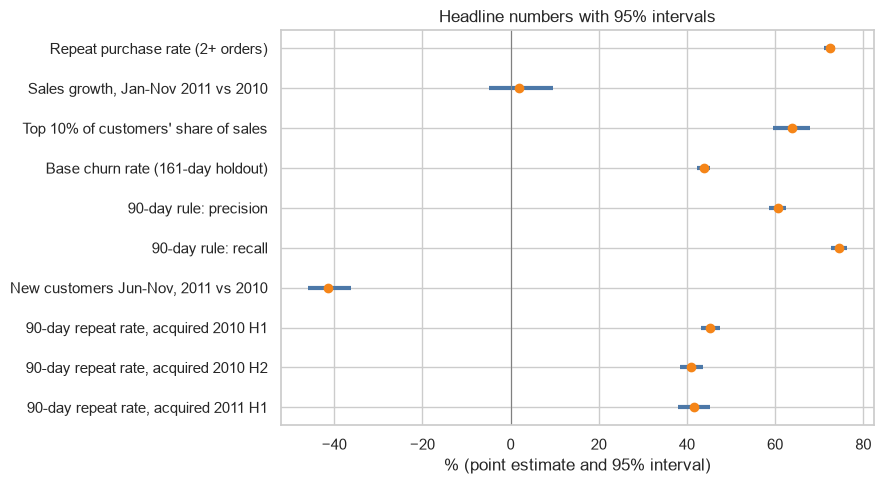

In [15]:
show = intervals.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(show))
ax.hlines(y, show.ci_low, show.ci_high, color="#4C78A8", lw=3)
ax.plot(show.estimate, y, "o", color="#F58518")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, show.metric)
ax.set_xlabel("% (point estimate and 95% interval)")
ax.set_title("Headline numbers with 95% intervals")
fig.tight_layout()
fig.savefig(FIGURES / "11_headline_intervals.png", dpi=150)
plt.show()

## 6. Save outputs

In [16]:
cutoff_table.to_csv(PROC / "robustness_cutoffs.csv")
intervals.to_csv(PROC / "robustness_intervals.csv", index=False)
pd.concat({"univariate": uni.set_index("feature"), "odds_ratios": odds}, axis=0).to_csv(PROC / "robustness_product_mix.csv")
comparison.loc["out-of-time AUC"] = [oot["baseline"], oot["with product features"]]
comparison.to_csv(PROC / "robustness_model_comparison.csv")
print("saved robustness_cutoffs.csv, robustness_intervals.csv, robustness_product_mix.csv, robustness_model_comparison.csv")

saved robustness_cutoffs.csv, robustness_intervals.csv, robustness_product_mix.csv, robustness_model_comparison.csv


## 7. Key takeaways

| Question | Result |
|---|---|
| **Does product mix matter for churn?** | A little. All five product features differ between churned and retained customers (Mann-Whitney p < 0.001), but most of that overlaps with how often and how much a customer buys. Adding them to the model improves the fit (likelihood-ratio chi-square 19.7, 5 df, p = 0.0014; AIC 4,752 to 4,742) but barely changes accuracy: AUC 0.786 to 0.788 in-sample and **0.778 to 0.778 out-of-time**. Higher average unit price (odds x1.31 per doubling, 95% CI 1.11-1.55) and bigger baskets (x1.16, 1.01-1.32) go with more churn; the Christmas share (x1.81, 0.79-4.15) and the number of products are not significant. |
| **Does the 90-day rule hold across cutoffs?** | Partly. Precision is 61-76% (the original 30 Jun 2011 cutoff is the lowest at 60.6%). Recall is **not stable: 45% and 49% at the Nov and Dec 2010 cutoffs against 75-76% at the three later ones**; revenue caught is 35-66%. Base churn falls from 55% to 44% across the cutoffs because the later holdouts include the autumn peak. The own-gap rule (1.5x, 3+ orders) keeps a lift of 1.3-1.6 at every cutoff. |
| **How sure are the headline numbers?** | Repeat rate 72.4% (95% CI 71.2-73.5). Sales growth +1.9% (**-4.9% to +9.7%**): "flat" is supported, but growth cannot be told apart from zero. Top 10% of customers' share 63.9% (59.5-67.8). Within the 30 Jun cutoff, rule precision 60.6% (58.6-62.6) and recall 74.6% (72.7-76.3). New customers Jun-Nov -41.3% (exact interval -46.0 to -36.3; 2011 is below 2010 in all 6 months, sign test p = 0.031). |
| **Is cohort quality stable?** | Mostly, with a qualification. The 90-day repeat rate is 45.3% (43.1-47.5) for 2010 H1 against 41.0% (38.4-43.6) for 2010 H2 (p = 0.013), then 41.5% (37.9-45.2) for 2011 H1 (p = 0.82 against 2010 H2). It dropped about 4 points between the two halves of 2010 and then held. Part of that drop may be left-censoring: customers first seen in early 2010 can include people who bought before the data starts. |

### What changes in the earlier conclusions
- The "silent > 90 days" rule is still useful (its precision is above the base churn rate at every cutoff), but **"catches 75% of churners" is true at the 30 Jun 2011 cutoff, not in general**. Recall depends on when the rule is applied, and that timing effect is much larger than the sampling interval.
- "Cohort quality is stable" should read "stable since mid-2010" (about 41%, down from 45% in early 2010).
- "Sales are flat" stands, but its 95% interval (-4.9% to +9.7%) is wide.
- Product mix does not change the churn rule: it is a small effect that does not improve out-of-time prediction.

### Caveats
- Product categories are derived (Christmas keywords, distinct stock codes), not an official category field.
- The five cutoffs overlap in time and share customers, so they are not independent tests. Churn is seasonal, so cutoffs near the autumn peak behave differently.
- Bootstrap intervals capture sampling noise only, not the choice of window or definition. The Poisson assumption behind the new-customer interval is a simplification; the 6-of-6 sign test needs fewer assumptions.
- Many tests were run without adjusting for multiple comparisons; treat single p-values near 0.03 with caution.